# 実験3 (ex003): 敵対的サンプル (Adversarial Examples) に対する Deep VIB の頑健性評価

本ノートブックでは，Alemi et al. (ICLR 2017) "Deep Variational Information Bottleneck" の **Section 4.2 (Behavior on Adversarial Examples, Figures 3, 4, 5, 6)** の再現実験を行う．

## 実験内容
1. **Targeted $L_2$ 最適化攻撃による「0 $\to$ 1」摂動実験 (Figure 3, Figure 4 の再現)**:
   - テストセット内の先頭10枚の「0」画像に対し，Carlini & Wagner (2016) の $L_2$ 最適化攻撃を用いてターゲットラベル「1」への誤分類を試みる．
   - 決定論的ベースライン (Det.)，Dropoutモデル，および各 $\beta$ の Deep VIB モデルについて，生成された敵対的サンプルの視覚的比較（赤枠＝攻撃成功，緑枠＝攻撃失敗・防御成功，紫枠＝別クラス誤分類）および摂動ノルム ($L_0, L_2, L_\infty$) の相対変化を評価する．
2. **Fast Gradient Sign (FGS) 攻撃に対する頑健性評価 (Figure 5 の再現)**:
   - テストセット先頭1,000枚に対し，$\epsilon \in \{0.35, 0.40, 0.45, 0.50\}$ の FGS 攻撃を実施し，決定論的モデルおよび Dropout モデルを基準とした相対正解率 (Relative Accuracy) を比較する．
3. **全クラスに対する Targeted / Untargeted $L_2$ 最適化攻撃の正解率評価 (Figure 6 の再現)**:
   - ランダムなターゲットラベルへの Targeted $L_2$ 攻撃および Untargeted $L_2$ 攻撃を実施し，$\beta$ の変化に伴う敵対的サンプル上の分類正解率を検証する．

In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from model import DeepVIB, DeterministicMLP
from utils import (
    set_seed,
    load_mnist_gpu,
    train_vib,
    train_deterministic,
    fgs_attack,
    evaluate_accuracy,
    cw_l2_attack,
    plot_zero_to_one_grid,
)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

os.makedirs("checkpoints", exist_ok=True)
os.makedirs("../report/img", exist_ok=True)

train_x, train_y, test_x, test_y = load_mnist_gpu("../datasets", device=device)

Using device: cuda (NVIDIA GeForce RTX 4080)


## 1. 学習済みモデル (Baseline, Dropout, 各 $\beta$ の Deep VIB) の読み込み・準備

Section 4.2.3 に従い，Section 4.1 (`ex001`) と同一の $K=256$ アーキテクチャの学習済みモデル（Polyak EMA パラメータ）を読み込む（未保存の場合はその場で200エポック学習する）．

In [2]:
ex001_ckpt_dir = "../ex001/checkpoints"

# 1. Deterministic Baseline
det_model = DeterministicMLP(dropout_rate=0.0).to(device)
det_ckpt = os.path.join(ex001_ckpt_dir, "baseline.pt")
if os.path.exists(det_ckpt):
    det_model.load_state_dict(torch.load(det_ckpt, map_location=device, weights_only=True))
else:
    set_seed(42)
    det_model = train_deterministic(det_model, train_x, train_y, epochs=200, desc="Train Baseline")
det_model.eval()

# 2. Dropout Model
drop_model = DeterministicMLP(dropout_rate=0.25).to(device)
drop_ckpt = os.path.join(ex001_ckpt_dir, "dropout.pt")
if os.path.exists(drop_ckpt):
    drop_model.load_state_dict(torch.load(drop_ckpt, map_location=device, weights_only=True))
else:
    set_seed(42)
    drop_model = train_deterministic(drop_model, train_x, train_y, epochs=200, desc="Train Dropout")
drop_model.eval()

# 3. VIB Models across beta
beta_list = [0.0, 1e-6, 1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1]
vib_models = {}
for beta in beta_list:
    m = DeepVIB(latent_dim=256).to(device)
    fname = f"vib_beta_{beta:.0e}.pt" if beta > 0 else "vib_beta_0.pt"
    ckpt_path = os.path.join(ex001_ckpt_dir, fname)
    if os.path.exists(ckpt_path):
        m.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    else:
        set_seed(42)
        m = train_vib(m, train_x, train_y, beta=beta, epochs=200, desc=f"Train VIB ({beta})")
    m.eval()
    vib_models[beta] = m

print(f"Clean Test Accuracy - Det: {evaluate_accuracy(det_model, test_x, test_y)*100:.2f}%, Dropout: {evaluate_accuracy(drop_model, test_x, test_y)*100:.2f}%")
for beta, m in vib_models.items():
    acc = evaluate_accuracy(m, test_x, test_y, mc_samples=12)
    print(f"Clean Test Accuracy - VIB (beta={beta:.0e}): {acc*100:.2f}%")

Clean Test Accuracy - Det: 98.60%, Dropout: 98.66%
Clean Test Accuracy - VIB (beta=0e+00): 98.52%
Clean Test Accuracy - VIB (beta=1e-06): 98.77%
Clean Test Accuracy - VIB (beta=1e-05): 98.75%
Clean Test Accuracy - VIB (beta=1e-04): 98.83%
Clean Test Accuracy - VIB (beta=3e-04): 98.81%
Clean Test Accuracy - VIB (beta=1e-03): 98.79%
Clean Test Accuracy - VIB (beta=3e-03): 98.71%
Clean Test Accuracy - VIB (beta=1e-02): 98.55%
Clean Test Accuracy - VIB (beta=1e-01): 98.58%


## 2. Targeted $L_2$ 最適化攻撃による「0 $\to$ 1」摂動実験 (Figure 3, Figure 4 の再現)

テストセット内の先頭10枚の「0」画像を選択し，ターゲットラベルを「1」として $L_2$ 最適化攻撃を実行する．

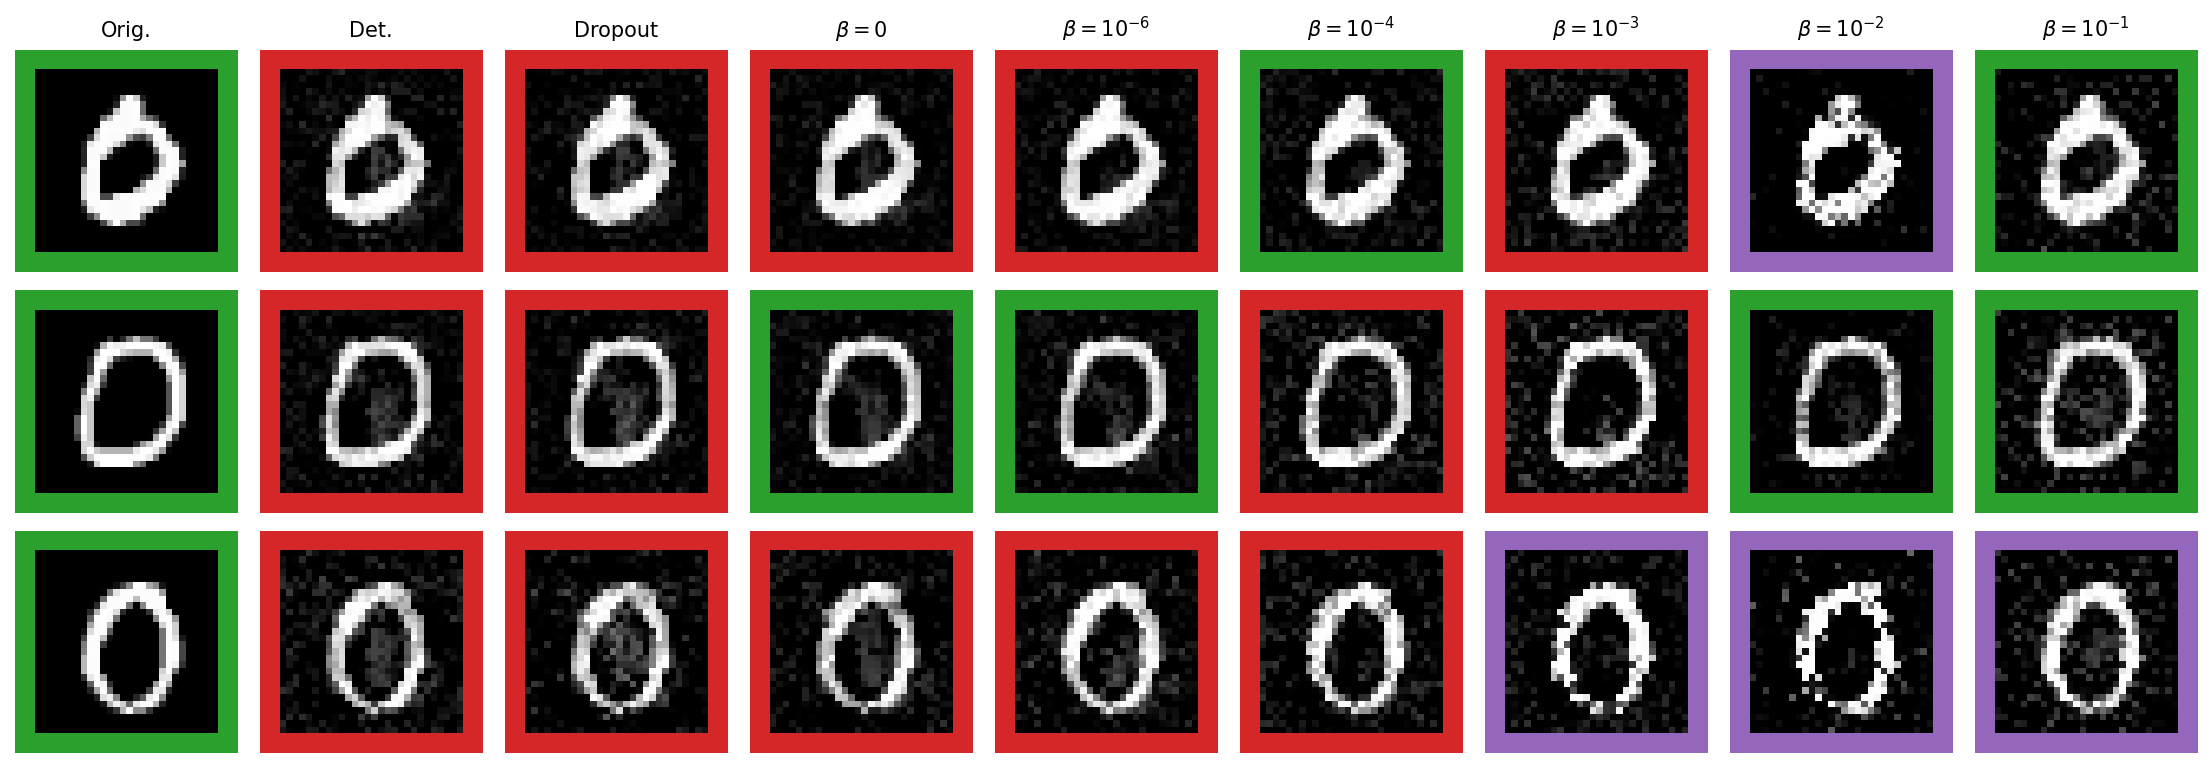

,beta,attack_success_rate,L0,L2,L_inf,L0_rel_det,L2_rel_det,Linf_rel_det,L0_rel_drop,L2_rel_drop,Linf_rel_drop
0,0.000000,0.9,266.899994,2.487763,0.447576,0.962843,0.970776,0.948542,0.997757,0.915683,0.935337
1,0.000001,0.5,246.100006,2.225293,0.463200,0.887807,0.868355,0.981654,0.920000,0.819075,0.967988
2,0.000010,0.5,257.200012,2.323471,0.463391,0.927850,0.906665,0.982059,0.961495,0.855211,0.968387
3,0.000100,0.5,262.100006,2.459131,0.484387,0.945527,0.959603,1.026555,0.979813,0.905144,1.012264
4,0.000300,0.5,262.700012,2.558927,0.503556,0.947691,0.998545,1.067181,0.982056,0.941877,1.052324
5,0.001000,0.5,248.699997,3.085595,0.570303,0.897186,1.204062,1.208636,0.929720,1.135730,1.191811
6,0.003000,0.2,233.625000,2.732257,0.544422,0.842803,1.066182,1.153786,0.873364,1.005675,1.137724
7,0.010000,0.0,157.000000,3.628916,0.776283,0.566378,1.416077,1.645166,0.586916,1.335713,1.622264
8,0.100000,0.0,207.222229,2.961808,0.551573,0.747555,1.155757,1.168942,0.774663,1.090167,1.152669


In [3]:
# テストセットから先頭 10 枚の「0」を抽出
zero_indices = torch.where(test_y == 0)[0][:10]
x_zeros = test_x[zero_indices]
y_target_ones = torch.ones(10, dtype=torch.long, device=device)

set_seed(42)
res_det_0to1 = cw_l2_attack(det_model, x_zeros, y_target_ones, targeted=True, c_weight=10.0, steps=100, lr=0.04, mc_samples=1)
res_drop_0to1 = cw_l2_attack(drop_model, x_zeros, y_target_ones, targeted=True, c_weight=10.0, steps=100, lr=0.04, mc_samples=1)

fig3_betas = [0.0, 1e-6, 1e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1]
res_vib_0to1 = {}
norm_rows = []

det_l0 = res_det_0to1["l0"].mean().item()
det_l2 = res_det_0to1["l2"].mean().item()
det_linf = res_det_0to1["l_inf"].mean().item()

drop_l0 = res_drop_0to1["l0"].mean().item()
drop_l2 = res_drop_0to1["l2"].mean().item()
drop_linf = res_drop_0to1["l_inf"].mean().item()

for beta in fig3_betas:
    set_seed(42)
    res = cw_l2_attack(vib_models[beta], x_zeros, y_target_ones, targeted=True, c_weight=10.0, steps=100, lr=0.04, mc_samples=12)
    res_vib_0to1[beta] = res
    mask = res["found"] if res["found"].any() else torch.ones_like(res["found"])
    l0_m = res["l0"][mask].mean().item()
    l2_m = res["l2"][mask].mean().item()
    linf_m = res["l_inf"][mask].mean().item()
    succ_rate = res["success"].float().mean().item()
    norm_rows.append({
        "beta": beta,
        "attack_success_rate": succ_rate,
        "L0": l0_m,
        "L2": l2_m,
        "L_inf": linf_m,
        "L0_rel_det": l0_m / max(det_l0, 1e-6),
        "L2_rel_det": l2_m / max(det_l2, 1e-6),
        "Linf_rel_det": linf_m / max(det_linf, 1e-6),
        "L0_rel_drop": l0_m / max(drop_l0, 1e-6),
        "L2_rel_drop": l2_m / max(drop_l2, 1e-6),
        "Linf_rel_drop": linf_m / max(drop_linf, 1e-6),
    })

df_norms = pd.DataFrame(norm_rows)
df_norms.to_csv("checkpoints/ex003_zero_to_one_norms.csv", index=False)

# Figure 3 のグリッド可視化
adv_grid_dict = {
    "Det.": res_det_0to1,
    "Dropout": res_drop_0to1,
    r"$\beta=0$": res_vib_0to1[0.0],
    r"$\beta=10^{-6}$": res_vib_0to1[1e-6],
    r"$\beta=10^{-4}$": res_vib_0to1[1e-4],
    r"$\beta=10^{-3}$": res_vib_0to1[1e-3],
    r"$\beta=10^{-2}$": res_vib_0to1[1e-2],
    r"$\beta=10^{-1}$": res_vib_0to1[1e-1],
}
plot_zero_to_one_grid(x_zeros, adv_grid_dict, save_path="../report/img/ex003_fig3_zero_to_one.png", num_rows=3)
df_norms

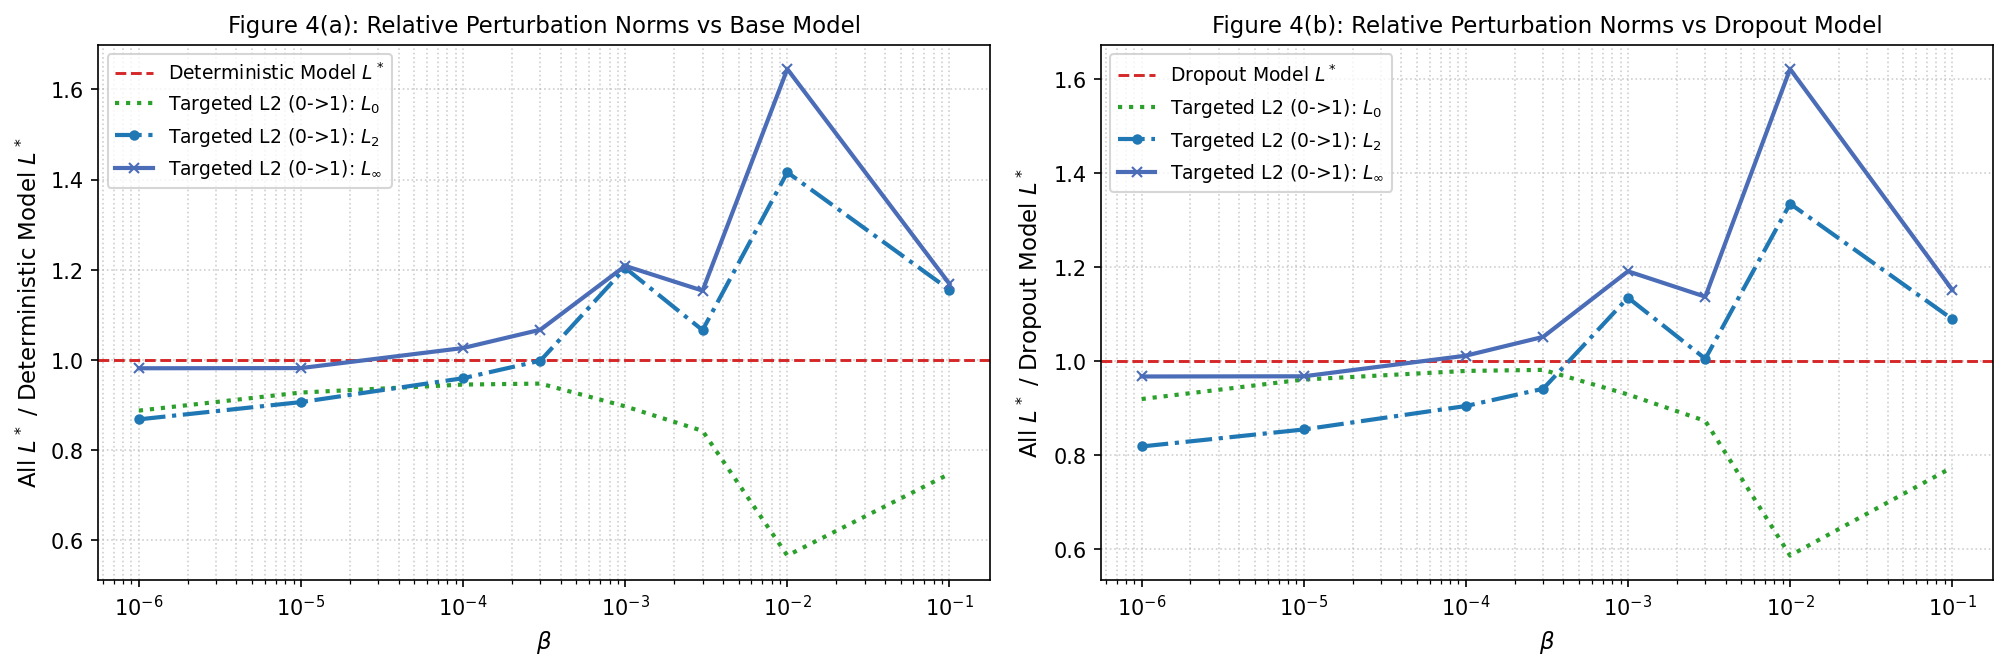

In [4]:
# Figure 4 (a), (b) の再現: 摂動ノルム (L0, L2, L_inf) の相対比較プロット
df_n_pos = df_norms[df_norms["beta"] > 0].copy()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

# (a) Normalized by Deterministic Model
ax = axes[0]
ax.axhline(1.0, color="#d62728", ls="--", lw=1.4, label="Deterministic Model $L^*$")
ax.plot(df_n_pos["beta"], df_n_pos["L0_rel_det"], ":", color="#2ca02c", lw=2.0, label="Targeted L2 (0->1): $L_0$")
ax.plot(df_n_pos["beta"], df_n_pos["L2_rel_det"], "-.", color="#1f77b4", lw=2.0, marker="o", ms=4, label="Targeted L2 (0->1): $L_2$")
ax.plot(df_n_pos["beta"], df_n_pos["Linf_rel_det"], "-", color="#4b6cb7", lw=2.0, marker="x", ms=5, label="Targeted L2 (0->1): $L_\\infty$")
ax.set_xscale("log")
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("All $L^*$ / Deterministic Model $L^*$", fontsize=11)
ax.set_title("Figure 4(a): Relative Perturbation Norms vs Base Model", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9)

# (b) Normalized by Dropout Model
ax = axes[1]
ax.axhline(1.0, color="#d62728", ls="--", lw=1.4, label="Dropout Model $L^*$")
ax.plot(df_n_pos["beta"], df_n_pos["L0_rel_drop"], ":", color="#2ca02c", lw=2.0, label="Targeted L2 (0->1): $L_0$")
ax.plot(df_n_pos["beta"], df_n_pos["L2_rel_drop"], "-.", color="#1f77b4", lw=2.0, marker="o", ms=4, label="Targeted L2 (0->1): $L_2$")
ax.plot(df_n_pos["beta"], df_n_pos["Linf_rel_drop"], "-", color="#4b6cb7", lw=2.0, marker="x", ms=5, label="Targeted L2 (0->1): $L_\\infty$")
ax.set_xscale("log")
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("All $L^*$ / Dropout Model $L^*$", fontsize=11)
ax.set_title("Figure 4(b): Relative Perturbation Norms vs Dropout Model", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../report/img/ex003_fig4_perturbation_norms.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Fast Gradient Sign (FGS) 攻撃に対する頑健性評価 (Figure 5 の再現)

論文 Section 4.2.4 (Figure 5) に従い，テストセットの先頭 1,000 枚の画像に対して $\epsilon \in \{0.35, 0.40, 0.45, 0.50\}$ の FGS 攻撃を実施し，ベースラインおよび Dropout モデルに対する相対正解率を評価する．

In [5]:
x_fgs = test_x[:1000]
y_fgs = test_y[:1000]
eps_list = [0.35, 0.40, 0.45, 0.50]

det_fgs_acc = {}
drop_fgs_acc = {}
for eps in eps_list:
    x_adv_det = fgs_attack(det_model, x_fgs, y_fgs, epsilon=eps, mc_samples=1)
    det_fgs_acc[eps] = max(evaluate_accuracy(det_model, x_adv_det, y_fgs, mc_samples=1), 1e-3)

    x_adv_drop = fgs_attack(drop_model, x_fgs, y_fgs, epsilon=eps, mc_samples=1)
    drop_fgs_acc[eps] = max(evaluate_accuracy(drop_model, x_adv_drop, y_fgs, mc_samples=1), 1e-3)
    print(f"FGS (eps={eps:.2f}) - Det Acc: {det_fgs_acc[eps]*100:.2f}%, Dropout Acc: {drop_fgs_acc[eps]*100:.2f}%")

fgs_rows = []
for beta in beta_list:
    row = {"beta": beta}
    for eps in eps_list:
        set_seed(42)
        x_adv_v = fgs_attack(vib_models[beta], x_fgs, y_fgs, epsilon=eps, mc_samples=12)
        acc_v = evaluate_accuracy(vib_models[beta], x_adv_v, y_fgs, mc_samples=12)
        row[f"acc_eps_{eps:.2f}"] = acc_v
        row[f"rel_det_{eps:.2f}"] = acc_v / det_fgs_acc[eps]
        row[f"rel_drop_{eps:.2f}"] = acc_v / drop_fgs_acc[eps]
    fgs_rows.append(row)

df_fgs = pd.DataFrame(fgs_rows)
df_fgs.to_csv("checkpoints/ex003_fgs_results.csv", index=False)
df_fgs

FGS (eps=0.35) - Det Acc: 13.40%, Dropout Acc: 18.50%
FGS (eps=0.40) - Det Acc: 8.00%, Dropout Acc: 15.20%
FGS (eps=0.45) - Det Acc: 4.90%, Dropout Acc: 12.20%
FGS (eps=0.50) - Det Acc: 3.00%, Dropout Acc: 10.20%


,beta,acc_eps_0.35,rel_det_0.35,rel_drop_0.35,acc_eps_0.40,rel_det_0.40,rel_drop_0.40,acc_eps_0.45,rel_det_0.45,rel_drop_0.45,acc_eps_0.50,rel_det_0.50,rel_drop_0.50
0,0.000000,0.133,0.992537,0.718919,0.069,0.8625,0.453947,0.050,1.020408,0.409836,0.033,1.100000,0.323529
1,0.000001,0.008,0.059701,0.043243,0.002,0.0250,0.013158,0.000,0.000000,0.000000,0.000,0.000000,0.000000
2,0.000010,0.026,0.194030,0.140541,0.008,0.1000,0.052632,0.005,0.102041,0.040984,0.002,0.066667,0.019608
3,0.000100,0.056,0.417910,0.302703,0.024,0.3000,0.157895,0.011,0.224490,0.090164,0.007,0.233333,0.068627
4,0.000300,0.070,0.522388,0.378378,0.019,0.2375,0.125000,0.009,0.183673,0.073770,0.003,0.100000,0.029412
5,0.001000,0.140,1.044776,0.756757,0.078,0.9750,0.513158,0.032,0.653061,0.262295,0.014,0.466667,0.137255
6,0.003000,0.221,1.649254,1.194595,0.148,1.8500,0.973684,0.097,1.979592,0.795082,0.067,2.233333,0.656863
7,0.010000,0.306,2.283582,1.654054,0.224,2.8000,1.473684,0.177,3.612245,1.450820,0.131,4.366667,1.284314
8,0.100000,0.238,1.776119,1.286486,0.179,2.2375,1.177632,0.129,2.632653,1.057377,0.103,3.433333,1.009804


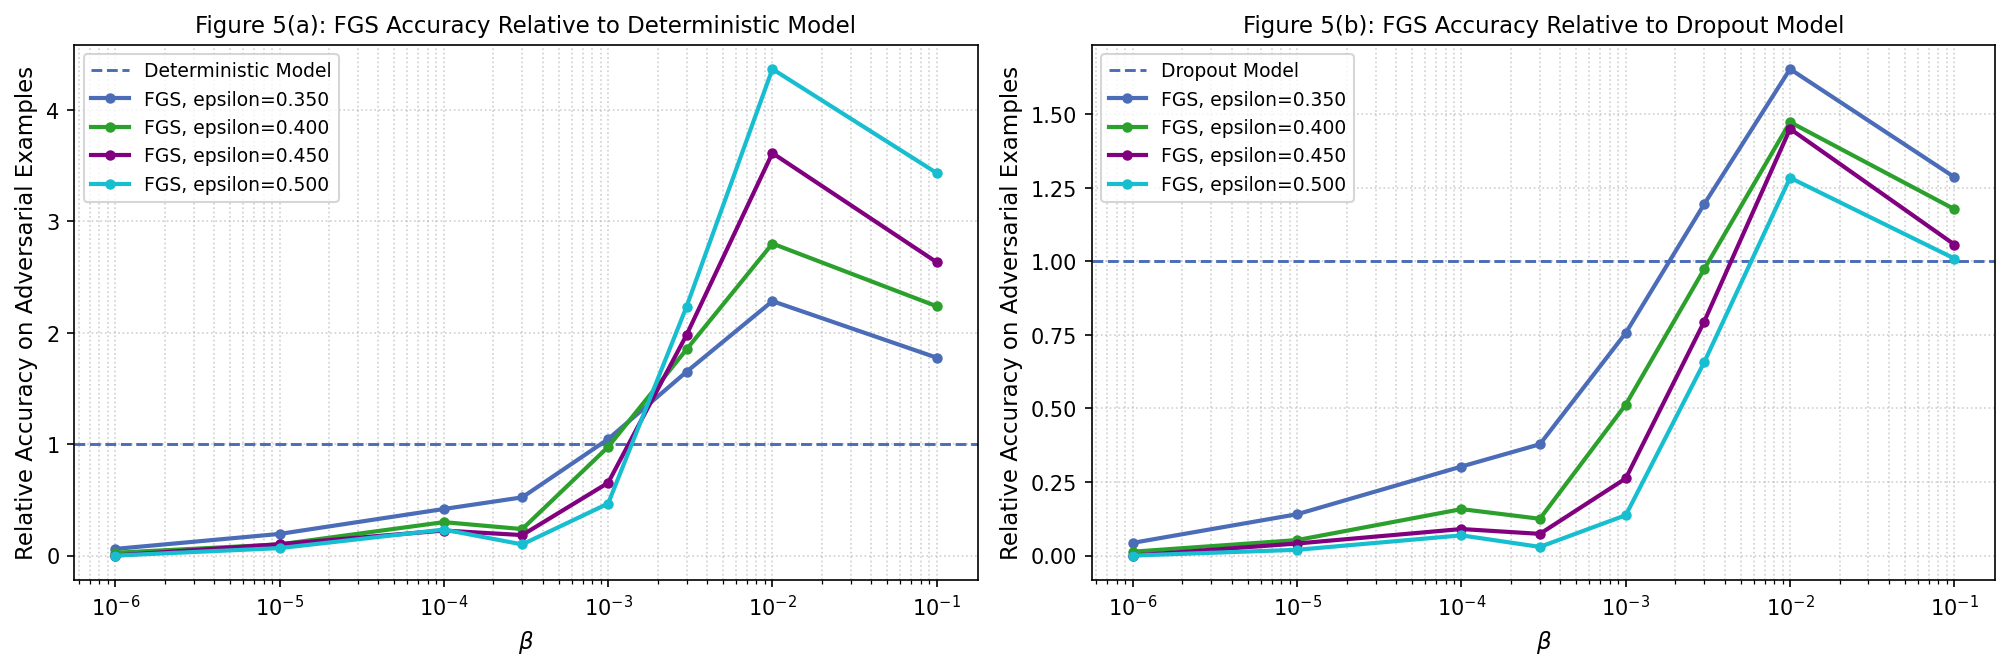

In [6]:
# Figure 5 (a), (b) のプロット
df_fgs_pos = df_fgs[df_fgs["beta"] > 0].copy()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
colors_eps = ["#4b6cb7", "#2ca02c", "#800080", "#17becf"]

# (a) Relative to Deterministic Model
ax = axes[0]
ax.axhline(1.0, color="#4b6cb7", ls="--", lw=1.4, label="Deterministic Model")
for eps, col in zip(eps_list, colors_eps):
    ax.plot(df_fgs_pos["beta"], df_fgs_pos[f"rel_det_{eps:.2f}"], "o-", color=col, lw=2, ms=4, label=f"FGS, epsilon={eps:.3f}")
ax.set_xscale("log")
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("Relative Accuracy on Adversarial Examples", fontsize=11)
ax.set_title("Figure 5(a): FGS Accuracy Relative to Deterministic Model", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9)

# (b) Relative to Dropout Model
ax = axes[1]
ax.axhline(1.0, color="#4b6cb7", ls="--", lw=1.4, label="Dropout Model")
for eps, col in zip(eps_list, colors_eps):
    ax.plot(df_fgs_pos["beta"], df_fgs_pos[f"rel_drop_{eps:.2f}"], "o-", color=col, lw=2, ms=4, label=f"FGS, epsilon={eps:.3f}")
ax.set_xscale("log")
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("Relative Accuracy on Adversarial Examples", fontsize=11)
ax.set_title("Figure 5(b): FGS Accuracy Relative to Dropout Model", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../report/img/ex003_fig5_fgs.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. 全クラスに対する Targeted / Untargeted $L_2$ 最適化攻撃の正解率評価 (Figure 6 の再現)

論文 Section 4.2.4 (Figure 6) に従い，テストセット画像に対して Untargeted $L_2$ 攻撃およびランダムな異クラスへの Targeted $L_2$ 攻撃を実行し，敵対的サンプル上の分類正解率 (Classification Accuracy on Adversarial Examples) を $\beta$ の関数として評価する．

In [7]:
# テストセット先頭 200 枚を用いて全クラス Targeted / Untargeted L2 最適化攻撃を評価
n_eval_cw = 200
x_cw = test_x[:n_eval_cw]
y_cw = test_y[:n_eval_cw]

# 正解ラベルと異なるランダムなターゲットラベルを生成
set_seed(42)
rand_offsets = torch.randint(1, 10, (n_eval_cw,), device=device)
y_target_rand = (y_cw + rand_offsets) % 10

# 決定論的モデル・Dropoutモデルの評価
res_det_targ = cw_l2_attack(det_model, x_cw, y_target_rand, targeted=True, c_weight=5.0, steps=100, lr=0.05, mc_samples=1)
res_det_untarg = cw_l2_attack(det_model, x_cw, y_cw, targeted=False, c_weight=5.0, steps=100, lr=0.05, mc_samples=1)
det_targ_acc = (res_det_targ["preds"] == y_cw).float().mean().item()
det_untarg_acc = (res_det_untarg["preds"] == y_cw).float().mean().item()

res_drop_targ = cw_l2_attack(drop_model, x_cw, y_target_rand, targeted=True, c_weight=5.0, steps=100, lr=0.05, mc_samples=1)
res_drop_untarg = cw_l2_attack(drop_model, x_cw, y_cw, targeted=False, c_weight=5.0, steps=100, lr=0.05, mc_samples=1)
drop_targ_acc = (res_drop_targ["preds"] == y_cw).float().mean().item()
drop_untarg_acc = (res_drop_untarg["preds"] == y_cw).float().mean().item()
print(f"Det Model L2 Adv Acc - Targeted: {det_targ_acc*100:.1f}%, Untargeted: {det_untarg_acc*100:.1f}%")
print(f"Dropout Model L2 Adv Acc - Targeted: {drop_targ_acc*100:.1f}%, Untargeted: {drop_untarg_acc*100:.1f}%")

cw_rows = []
for beta in beta_list:
    set_seed(42)
    r_targ = cw_l2_attack(vib_models[beta], x_cw, y_target_rand, targeted=True, c_weight=5.0, steps=100, lr=0.05, mc_samples=12)
    r_untarg = cw_l2_attack(vib_models[beta], x_cw, y_cw, targeted=False, c_weight=5.0, steps=100, lr=0.05, mc_samples=12)

    # Targeted 攻撃に対する頑健性 (ターゲットクラスへの誘導を防ぎ正解を維持した割合，または攻撃失敗率 1 - success)
    acc_targ = (1.0 - r_targ["success"].float()).mean().item()
    acc_untarg = (1.0 - r_untarg["success"].float()).mean().item()
    cw_rows.append({
        "beta": beta,
        "targeted_robust_acc": acc_targ,
        "untargeted_robust_acc": acc_untarg,
        "targeted_l2_mean": r_targ["l2"].mean().item(),
        "untargeted_l2_mean": r_untarg["l2"].mean().item(),
    })
    print(f"[VIB beta={beta:.0e}] L2 Adv Robustness - Targeted: {acc_targ*100:.1f}%, Untargeted: {acc_untarg*100:.1f}%")

df_cw = pd.DataFrame(cw_rows)
df_cw.to_csv("checkpoints/ex003_cw_l2_results.csv", index=False)
df_cw

Det Model L2 Adv Acc - Targeted: 0.0%, Untargeted: 0.0%
Dropout Model L2 Adv Acc - Targeted: 0.0%, Untargeted: 0.0%
[VIB beta=0e+00] L2 Adv Robustness - Targeted: 0.0%, Untargeted: 1.5%
[VIB beta=1e-06] L2 Adv Robustness - Targeted: 22.0%, Untargeted: 24.0%
[VIB beta=1e-05] L2 Adv Robustness - Targeted: 25.0%, Untargeted: 23.5%
[VIB beta=1e-04] L2 Adv Robustness - Targeted: 25.5%, Untargeted: 24.5%
[VIB beta=3e-04] L2 Adv Robustness - Targeted: 32.5%, Untargeted: 23.0%
[VIB beta=1e-03] L2 Adv Robustness - Targeted: 31.0%, Untargeted: 25.0%
[VIB beta=3e-03] L2 Adv Robustness - Targeted: 43.0%, Untargeted: 29.0%
[VIB beta=1e-02] L2 Adv Robustness - Targeted: 46.5%, Untargeted: 36.0%
[VIB beta=1e-01] L2 Adv Robustness - Targeted: 71.5%, Untargeted: 43.5%


,beta,targeted_robust_acc,untargeted_robust_acc,targeted_l2_mean,untargeted_l2_mean
0,0.000000,0.000,0.015,3.660011,2.514923
1,0.000001,0.220,0.240,2.785399,2.066625
2,0.000010,0.250,0.235,2.573274,2.034062
3,0.000100,0.255,0.245,2.546131,2.017847
4,0.000300,0.325,0.230,2.539747,2.006519
5,0.001000,0.310,0.250,2.581613,2.017518
6,0.003000,0.430,0.290,2.590474,1.983217
7,0.010000,0.465,0.360,2.536590,1.981654
8,0.100000,0.715,0.435,2.059587,1.594989


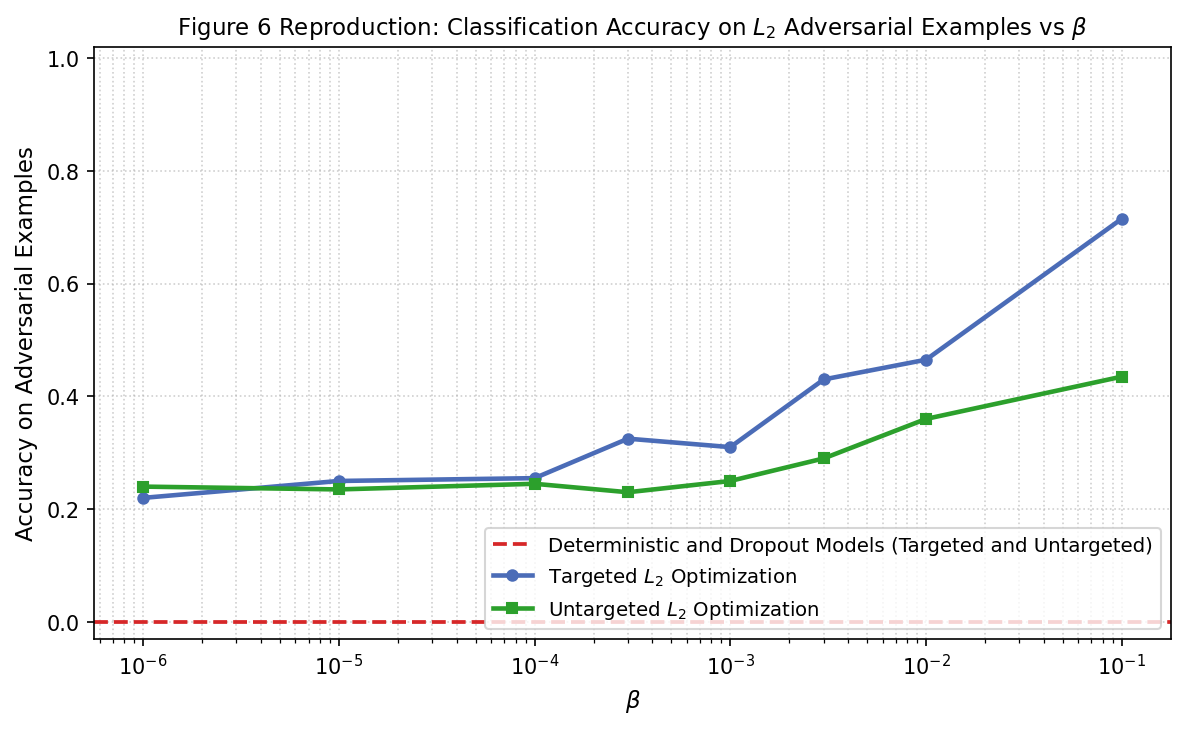

In [8]:
# Figure 6 の再現プロット
df_cw_pos = df_cw[df_cw["beta"] > 0].copy()

fig, ax = plt.subplots(figsize=(8.0, 5.0))
ax.axhline(det_targ_acc, color="#d62728", ls="--", lw=1.8, label="Deterministic and Dropout Models (Targeted and Untargeted)")
ax.plot(df_cw_pos["beta"], df_cw_pos["targeted_robust_acc"], "o-", color="#4b6cb7", lw=2.2, ms=5, label="Targeted $L_2$ Optimization")
ax.plot(df_cw_pos["beta"], df_cw_pos["untargeted_robust_acc"], "s-", color="#2ca02c", lw=2.2, ms=5, label="Untargeted $L_2$ Optimization")
ax.set_xscale("log")
ax.set_ylim(-0.03, 1.02)
ax.set_xlabel("$\\beta$", fontsize=11)
ax.set_ylabel("Accuracy on Adversarial Examples", fontsize=11)
ax.set_title("Figure 6 Reproduction: Classification Accuracy on $L_2$ Adversarial Examples vs $\\beta$", fontsize=11)
ax.grid(True, which="both", ls=":", alpha=0.6)
ax.legend(fontsize=9.5, loc="lower right")

plt.tight_layout()
plt.savefig("../report/img/ex003_fig6_cw_l2_accuracy.png", dpi=180, bbox_inches="tight")
plt.show()